## 1. Mount google drive

In [1]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


## 2. Import Dependencies

In [2]:
import os
import re
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from pathlib import Path
from PIL import Image

from collections import Counter

plt.rcParams["figure.figsize"] = (12, 6)

print("Environment initialized.")

Environment initialized.


## 3. Configure project and dataset path

In [23]:
PROJECT_ROOT = Path(
    "/content/drive/MyDrive/AAI-521/project"
)

DATASET_ROOT = PROJECT_ROOT / "datasets/camvid"

IMAGE_DIR = DATASET_ROOT / "images"
MASK_DIR = DATASET_ROOT / "masks"
CLASS_DICT_FILE = DATASET_ROOT / "label_colors.txt"

RESULTS_DIR = DATASET_ROOT / "outputs"

RESULTS_DIR.mkdir(
    parents=True,
    exist_ok=True
)

# Initial threshold for image-level class presence
MIN_PIXELS_PER_CLASS = 20

# Special ID for pixels that do not belong to a usable class
VOID_CLASS_ID = 255

# Image and mask naming convention
MASK_SUFFIX = "_L"

assert IMAGE_DIR.exists(), f"Missing image directory: {IMAGE_DIR}"
assert MASK_DIR.exists(), f"Missing mask directory: {MASK_DIR}"
assert CLASS_DICT_FILE.exists(), f"Missing dictionary: {CLASS_DICT_FILE}"

print("Dataset paths validated.")

Dataset paths validated.


## 4. Explore directory structure and file counts

In [24]:
IMAGE_EXTENSIONS = {".png", ".jpg", ".jpeg", ".bmp"}

image_files = sorted([
    p for p in IMAGE_DIR.iterdir()
    if p.is_file() and p.suffix.lower() in IMAGE_EXTENSIONS
])

mask_files = sorted([
    p for p in MASK_DIR.iterdir()
    if p.is_file() and p.suffix.lower() in IMAGE_EXTENSIONS
])

print("Raw images:", len(image_files))
print("Segmentation masks:", len(mask_files))

print("\nSample raw images:")
for path in image_files[:5]:
    print(path.name)

print("\nSample masks:")
for path in mask_files[:5]:
    print(path.name)

Raw images: 701
Segmentation masks: 701

Sample raw images:
0001TP_006690.png
0001TP_006720.png
0001TP_006750.png
0001TP_006780.png
0001TP_006810.png

Sample masks:
0001TP_006690_L.png
0001TP_006720_L.png
0001TP_006750_L.png
0001TP_006780_L.png
0001TP_006810_L.png


## 5. Pair raw images and masks

In [5]:
image_map = {
    p.stem: p
    for p in image_files
}

mask_map = {}

for mask_path in mask_files:

    if not mask_path.stem.endswith(MASK_SUFFIX):
        continue

    image_stem = mask_path.stem[:-len(MASK_SUFFIX)]

    mask_map[image_stem] = mask_path


common_names = sorted(
    set(image_map) & set(mask_map)
)

missing_masks = sorted(
    set(image_map) - set(mask_map)
)

missing_images = sorted(
    set(mask_map) - set(image_map)
)

dataset_records = [
    {
        "filename": name,
        "image_path": image_map[name],
        "mask_path": mask_map[name]
    }
    for name in common_names
]

print("Matched image-mask pairs:", len(dataset_records))
print("Images without masks:", len(missing_masks))
print("Masks without images:", len(missing_images))

assert len(dataset_records) > 0, "No valid image-mask pairs found."

Matched image-mask pairs: 701
Images without masks: 0
Masks without images: 0


## 6. Validate image and mask properties

In [6]:
inspection = []

for record in dataset_records:

    with Image.open(record["image_path"]) as image:
        image_size = image.size
        image_mode = image.mode

    with Image.open(record["mask_path"]) as mask:
        mask_size = mask.size
        mask_mode = mask.mode

    inspection.append({
        "filename": record["filename"],
        "image_size": image_size,
        "mask_size": mask_size,
        "image_mode": image_mode,
        "mask_mode": mask_mode,
        "dimensions_match": image_size == mask_size,
        "is_expected_size": image_size == (960, 720)
    })

inspection_df = pd.DataFrame(inspection)

display(inspection_df.head(10))

print("\nImage dimensions:")
display(inspection_df["image_size"].value_counts())

print("\nImage modes:")
display(inspection_df["image_mode"].value_counts())

print("\nMask modes:")
display(inspection_df["mask_mode"].value_counts())

print("\nDimension mismatches:",
      (~inspection_df["dimensions_match"]).sum())

print("Unexpected image dimensions:",
      (~inspection_df["is_expected_size"]).sum())

,filename,image_size,mask_size,image_mode,mask_mode,dimensions_match,is_expected_size
0,0001TP_006690,"(960, 720)","(960, 720)",RGB,RGB,True,True
1,0001TP_006720,"(960, 720)","(960, 720)",RGB,RGB,True,True
2,0001TP_006750,"(960, 720)","(960, 720)",RGB,RGB,True,True
3,0001TP_006780,"(960, 720)","(960, 720)",RGB,RGB,True,True
4,0001TP_006810,"(960, 720)","(960, 720)",RGB,RGB,True,True
5,0001TP_006840,"(960, 720)","(960, 720)",RGB,RGB,True,True
6,0001TP_006870,"(960, 720)","(960, 720)",RGB,RGB,True,True
7,0001TP_006900,"(960, 720)","(960, 720)",RGB,RGB,True,True
8,0001TP_006930,"(960, 720)","(960, 720)",RGB,RGB,True,True
9,0001TP_006960,"(960, 720)","(960, 720)",RGB,RGB,True,True



Image dimensions:


,count
image_size,
"(960, 720)",701



Image modes:


,count
image_mode,
RGB,701



Mask modes:


,count
mask_mode,
RGB,701



Dimension mismatches: 0
Unexpected image dimensions: 0


## 7. Load the 32-class RGB dictionary

In [7]:
class_df = pd.read_csv(
    CLASS_DICT_FILE,
    #sep=None,
    sep=r"\s+",
    engine="python",
    header=None,
    names=["r", "g", "b", "name"]  # Assign custom names here
)

print("Dictionary columns:")
print(class_df.columns.tolist())

display(class_df.head(35))

Dictionary columns:
['r', 'g', 'b', 'name']


,r,g,b,name
0,64,128,64,Animal
1,192,0,128,Archway
2,0,128,192,Bicyclist
3,0,128,64,Bridge
4,128,0,0,Building
5,64,0,128,Car
6,64,0,192,CartLuggagePram
7,192,128,64,Child
8,192,192,128,Column_Pole
9,64,64,128,Fence


In [8]:
#Validate the dictionary

required_columns = {"r", "g", "b", "name"}

assert required_columns.issubset(
    set(class_df.columns)
), "Unexpected class dictionary format."

class_df["name"] = class_df["name"].astype(str).str.strip()

for col in ["r", "g", "b"]:

    class_df[col] = pd.to_numeric(
        class_df[col],
        errors="raise"
    ).astype(int)

    assert class_df[col].between(0, 255).all()

assert not class_df["name"].duplicated().any()

assert not class_df[["r", "g", "b"]].duplicated().any()

print("Number of semantic classes:", len(class_df))

assert len(class_df) == 32, (
    "Expected 32 classes. Check the dictionary and its parsing."
)

Number of semantic classes: 32


## 8. Generate RGB-to-class-ID mapping

In [9]:
class_names = [
    name
    for name in class_df["name"].tolist()
    if name.lower() != "void"
]

CLASS_TO_ID = {
    name: idx
    for idx, name in enumerate(class_names)
}

CLASS_TO_RGB = {
    row["name"]: (
        int(row["r"]),
        int(row["g"]),
        int(row["b"])
    )
    for _, row in class_df.iterrows()
}

RGB_TO_CLASS_ID = {
    rgb: (
        VOID_CLASS_ID
        if name.lower() == "void"
        else CLASS_TO_ID[name]
    )
    for name, rgb in CLASS_TO_RGB.items()
}

CLASS_ID_TO_NAME = {
    idx: name
    for name, idx in CLASS_TO_ID.items()
}

print("Usable classes:", len(CLASS_TO_ID))
print("Void ID:", VOID_CLASS_ID)

print("\nClass mapping:")

for name, idx in CLASS_TO_ID.items():
    print(idx, name, CLASS_TO_RGB[name])

Usable classes: 31
Void ID: 255

Class mapping:
0 Animal (64, 128, 64)
1 Archway (192, 0, 128)
2 Bicyclist (0, 128, 192)
3 Bridge (0, 128, 64)
4 Building (128, 0, 0)
5 Car (64, 0, 128)
6 CartLuggagePram (64, 0, 192)
7 Child (192, 128, 64)
8 Column_Pole (192, 192, 128)
9 Fence (64, 64, 128)
10 LaneMkgsDriv (128, 0, 192)
11 LaneMkgsNonDriv (192, 0, 64)
12 Misc_Text (128, 128, 64)
13 MotorcycleScooter (192, 0, 192)
14 OtherMoving (128, 64, 64)
15 ParkingBlock (64, 192, 128)
16 Pedestrian (64, 64, 0)
17 Road (128, 64, 128)
18 RoadShoulder (128, 128, 192)
19 Sidewalk (0, 0, 192)
20 SignSymbol (192, 128, 128)
21 Sky (128, 128, 128)
22 SUVPickupTruck (64, 128, 192)
23 TrafficCone (0, 0, 64)
24 TrafficLight (0, 64, 64)
25 Train (192, 64, 128)
26 Tree (128, 128, 0)
27 Truck_Bus (192, 128, 192)
28 Tunnel (64, 0, 64)
29 VegetationMisc (192, 192, 0)
30 Wall (64, 192, 0)


## 9. Visualize raw images and RGB masks

In [10]:
def visualize_samples(records, n=4):
    n = min(n, len(records))

    fig, axes = plt.subplots(
        n, 2,
        figsize=(15, 4*n)
    )

    if n == 1:
        axes = np.expand_dims(axes, axis=0)

    for i, record in enumerate(records[:n]):

        image = Image.open(
            record["image_path"]
        ).convert("RGB")

        mask = Image.open(
            record["mask_path"]
        )

        axes[i, 0].imshow(image)
        axes[i, 0].set_title(
            f"Raw image: {record['filename']}"
        )

        axes[i, 1].imshow(mask)
        axes[i, 1].set_title(
            "RGB segmentation mask"
        )

        axes[i, 0].axis("off")
        axes[i, 1].axis("off")

    plt.tight_layout()
    plt.show()


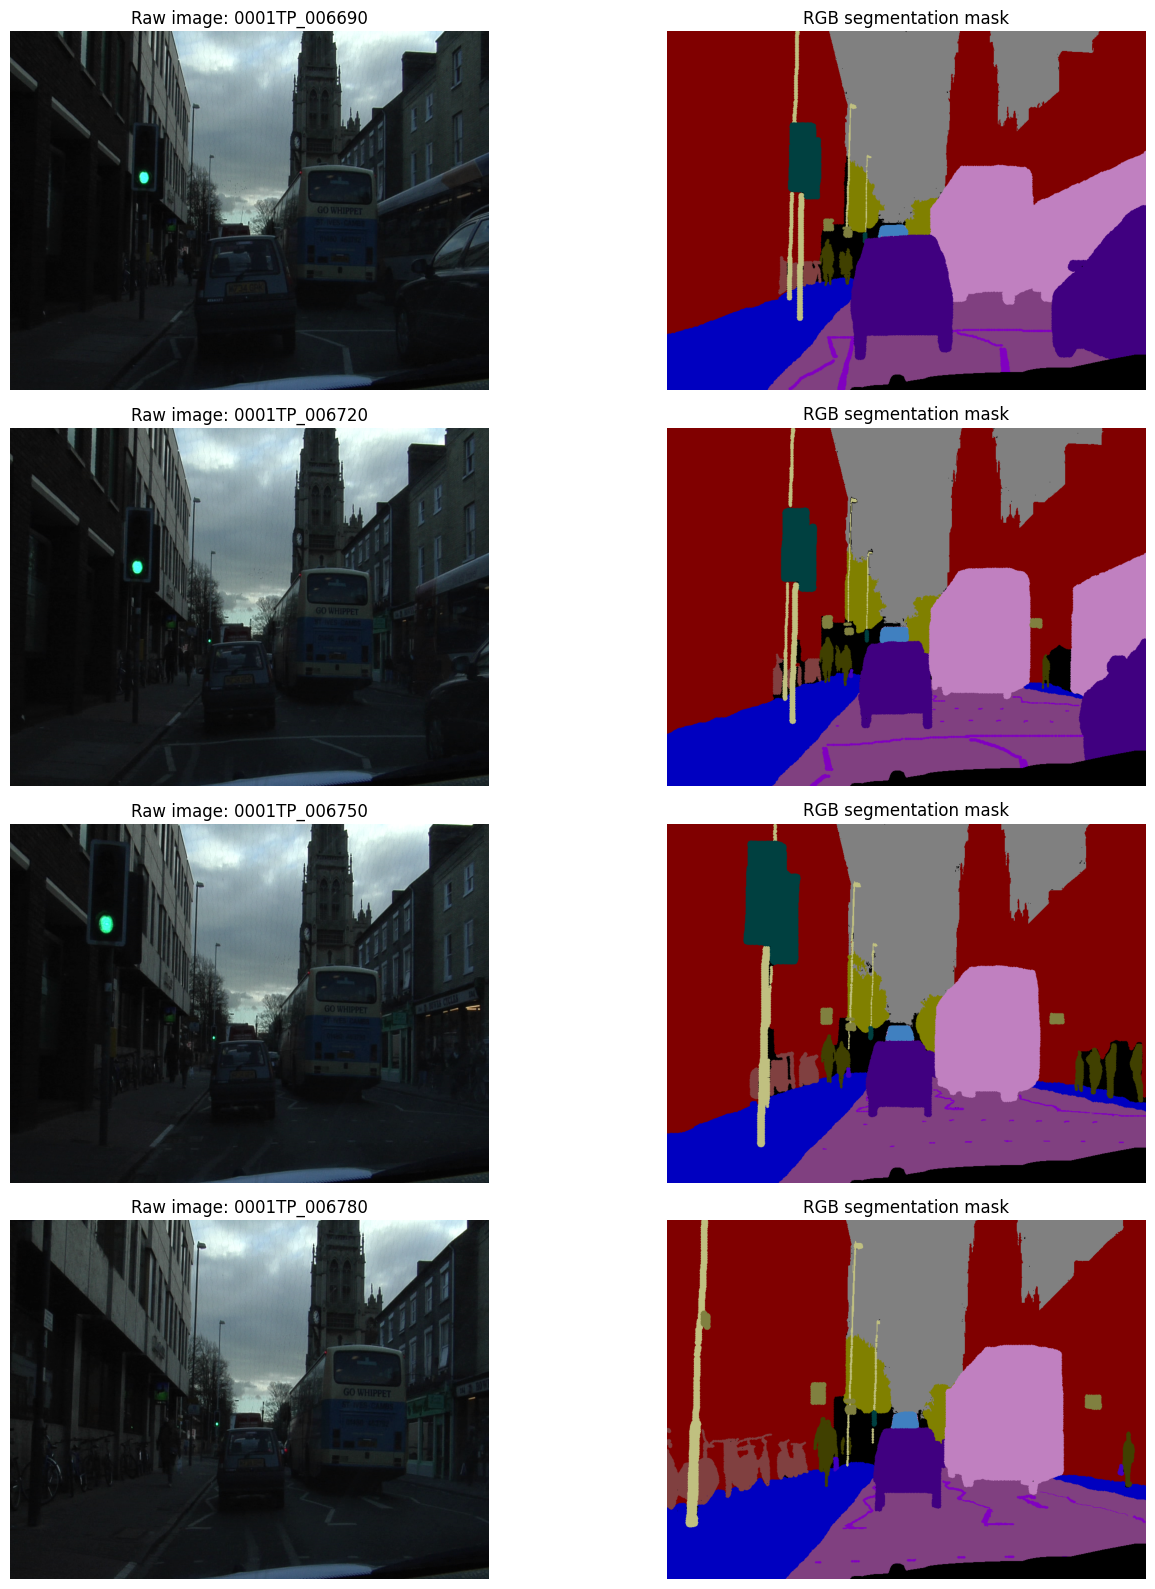

In [ ]:
visualize_samples(dataset_records, n=4)

## 10. Validate RGB mask values against the dictionary

In [11]:
def rgb_to_int(rgb):

    r, g, b = rgb

    return (r << 16) | (g << 8) | b

RGB_TO_CLASS_ID_INT = {
    rgb_to_int(rgb): class_id
    for rgb, class_id in RGB_TO_CLASS_ID.items()
}

def inspect_mask_colors(mask_path):
    mask = np.array(
        Image.open(mask_path)
    )

    assert mask.ndim == 3 and mask.shape[2] == 3, (
        f"Expected RGB mask: {mask_path}"
    )

    encoded = (
        (mask[:, :, 0].astype(np.int64) << 16) |
        (mask[:, :, 1].astype(np.int64) << 8) |
        mask[:, :, 2].astype(np.int64)
    )

    values, counts = np.unique(
        encoded,
        return_counts=True
    )

    return dict(zip(values.tolist(), counts.tolist()))

sample_colors = inspect_mask_colors(
    dataset_records[0]["mask_path"]
)

unknown_colors = [
    color
    for color in sample_colors
    if color not in RGB_TO_CLASS_ID_INT
]

print("Unique colors in sample mask:", len(sample_colors))
print("Unknown colors:", len(unknown_colors))

Unique colors in sample mask: 15
Unknown colors: 0


In [12]:
#Validate all masks
mask_color_counts = {}
unknown_color_counts = Counter()

for record in dataset_records:
    color_counts = inspect_mask_colors(
        record["mask_path"]
    )
    mask_color_counts[record["mask_path"]] = color_counts

    for color, count in color_counts.items():

        if color not in RGB_TO_CLASS_ID_INT:
            unknown_color_counts[color] += count


print("Total unknown RGB colors:",
      len(unknown_color_counts))

for color, count in unknown_color_counts.most_common(20):

    rgb = (
        (color >> 16) & 255,
        (color >> 8) & 255,
        color & 255
    )

    print(rgb, "Pixel count:", count)

Total unknown RGB colors: 55
(128, 128, 51) Pixel count: 21
(26, 26, 0) Pixel count: 15
(51, 51, 0) Pixel count: 14
(77, 77, 0) Pixel count: 14
(128, 128, 26) Pixel count: 14
(128, 128, 102) Pixel count: 12
(2, 2, 2) Pixel count: 5
(102, 102, 0) Pixel count: 5
(128, 128, 77) Pixel count: 5
(48, 48, 48) Pixel count: 4
(77, 77, 77) Pixel count: 4
(128, 128, 3) Pixel count: 4
(2, 2, 0) Pixel count: 3
(48, 48, 0) Pixel count: 3
(92, 92, 92) Pixel count: 3
(15, 15, 15) Pixel count: 2
(26, 26, 26) Pixel count: 2
(51, 51, 51) Pixel count: 2
(60, 60, 0) Pixel count: 2
(108, 108, 0) Pixel count: 2


## 11. Generate class pixel counts per image

In [14]:
def extract_class_pixel_counts(mask_path):
    # color_counts = inspect_mask_colors(mask_path)
    color_counts = mask_color_counts[mask_path]

    class_counts = {
        name: 0
        for name in CLASS_TO_ID
    }

    void_pixels = 0

    for color, pixel_count in color_counts.items():
        class_id = RGB_TO_CLASS_ID_INT.get(color)

        # Map unknown colors to Void instead of raising an error
        if class_id is None or class_id == VOID_CLASS_ID:
            void_pixels += pixel_count
        else:
            class_name = CLASS_ID_TO_NAME[class_id]
            class_counts[class_name] += pixel_count

    return class_counts, void_pixels

In [15]:
# Test against one image
sample_counts, sample_void = extract_class_pixel_counts(
    dataset_records[0]["mask_path"]
)

print("Image:", dataset_records[0]["filename"])

for class_name, count in sample_counts.items():
    if count > 0:
        print(class_name, ":", count)

print("Void pixels:", sample_void)

Image: 0001TP_006690
Building : 259032
Car : 81057
Column_Pole : 7609
LaneMkgsDriv : 4538
Misc_Text : 909
OtherMoving : 3016
Pedestrian : 2960
Road : 59896
Sidewalk : 47344
Sky : 95196
SUVPickupTruck : 1234
TrafficLight : 9246
Tree : 9264
Truck_Bus : 81296
Void pixels: 28603


## 12. Generate image-level multi-label targets

In [25]:
def generate_image_labels(
    mask_path,
    min_pixels=MIN_PIXELS_PER_CLASS
):

    class_counts, void_pixels = (
        extract_class_pixel_counts(mask_path)
    )

    labels = {
        class_name: int(count >= min_pixels)
        for class_name, count in class_counts.items()
    }

    return labels, class_counts, void_pixels

In [17]:
#Generate label for entire dataset

label_records = []

for record in dataset_records:

    labels, counts, void_pixels = generate_image_labels(
        record["mask_path"]
    )

    row = {
        "image": record["image_path"].as_posix(),
        "filename": record["filename"],
        "mask": record["mask_path"].as_posix(),
        **labels
    }

    label_records.append(row)


image_labels_df = pd.DataFrame(label_records)

display(image_labels_df.head(10))

,image,filename,mask,Animal,Archway,Bicyclist,Bridge,Building,Car,CartLuggagePram,...,Sky,SUVPickupTruck,TrafficCone,TrafficLight,Train,Tree,Truck_Bus,Tunnel,VegetationMisc,Wall
0,/content/drive/MyDrive/AAI-521/project/dataset...,0001TP_006690,/content/drive/MyDrive/AAI-521/project/dataset...,0,0,0,0,1,1,0,...,1,1,0,1,0,1,1,0,0,0
1,/content/drive/MyDrive/AAI-521/project/dataset...,0001TP_006720,/content/drive/MyDrive/AAI-521/project/dataset...,0,0,0,0,1,1,1,...,1,1,0,1,0,1,1,0,0,0
2,/content/drive/MyDrive/AAI-521/project/dataset...,0001TP_006750,/content/drive/MyDrive/AAI-521/project/dataset...,0,0,0,0,1,1,1,...,1,1,0,1,0,1,1,0,0,0
3,/content/drive/MyDrive/AAI-521/project/dataset...,0001TP_006780,/content/drive/MyDrive/AAI-521/project/dataset...,0,0,0,0,1,1,1,...,1,1,0,1,0,1,1,0,0,0
4,/content/drive/MyDrive/AAI-521/project/dataset...,0001TP_006810,/content/drive/MyDrive/AAI-521/project/dataset...,0,0,1,0,1,1,1,...,1,1,0,1,0,1,1,0,0,0
5,/content/drive/MyDrive/AAI-521/project/dataset...,0001TP_006840,/content/drive/MyDrive/AAI-521/project/dataset...,0,0,1,0,1,1,1,...,1,1,0,1,0,1,1,0,0,1
6,/content/drive/MyDrive/AAI-521/project/dataset...,0001TP_006870,/content/drive/MyDrive/AAI-521/project/dataset...,0,0,1,0,1,1,0,...,1,1,0,1,0,1,1,0,0,1
7,/content/drive/MyDrive/AAI-521/project/dataset...,0001TP_006900,/content/drive/MyDrive/AAI-521/project/dataset...,0,0,0,0,1,1,0,...,1,1,0,1,0,1,1,0,0,1
8,/content/drive/MyDrive/AAI-521/project/dataset...,0001TP_006930,/content/drive/MyDrive/AAI-521/project/dataset...,0,0,1,0,1,1,0,...,1,1,0,1,0,1,1,0,0,1
9,/content/drive/MyDrive/AAI-521/project/dataset...,0001TP_006960,/content/drive/MyDrive/AAI-521/project/dataset...,0,0,1,0,1,1,1,...,1,1,0,1,0,1,1,0,0,1


In [33]:
# Preserve pixel counts for threshold experiments

detailed_label_records = []

for record in dataset_records:

    class_counts, void_pixels = (
        extract_class_pixel_counts(
            record["mask_path"]
        )
    )

    row = {
        "filename": record["filename"],
        "image": record["image_path"].as_posix(),
        "mask": record["mask_path"].as_posix(),
        "void_pixels": void_pixels
    }

    # Preserve raw counts
    for class_name, count in class_counts.items():

        row[f"{class_name}_pixels"] = count

    # Generate initial binary labels
    for class_name, count in class_counts.items():

        row[class_name] = int(
            count >= MIN_PIXELS_PER_CLASS
        )

    detailed_label_records.append(row)


detailed_labels_df = pd.DataFrame(detailed_label_records)
display(detailed_labels_df.head(10))

,filename,image,mask,void_pixels,Animal_pixels,Archway_pixels,Bicyclist_pixels,Bridge_pixels,Building_pixels,Car_pixels,...,Sky,SUVPickupTruck,TrafficCone,TrafficLight,Train,Tree,Truck_Bus,Tunnel,VegetationMisc,Wall
0,0001TP_006690,/content/drive/MyDrive/AAI-521/project/dataset...,/content/drive/MyDrive/AAI-521/project/dataset...,28603,0,0,0,0,259032,81057,...,1,1,0,1,0,1,1,0,0,0
1,0001TP_006720,/content/drive/MyDrive/AAI-521/project/dataset...,/content/drive/MyDrive/AAI-521/project/dataset...,33730,0,0,0,0,272534,43775,...,1,1,0,1,0,1,1,0,0,0
2,0001TP_006750,/content/drive/MyDrive/AAI-521/project/dataset...,/content/drive/MyDrive/AAI-521/project/dataset...,36204,0,0,0,0,283927,17372,...,1,1,0,1,0,1,1,0,0,0
3,0001TP_006780,/content/drive/MyDrive/AAI-521/project/dataset...,/content/drive/MyDrive/AAI-521/project/dataset...,31684,0,0,0,0,267706,18042,...,1,1,0,1,0,1,1,0,0,0
4,0001TP_006810,/content/drive/MyDrive/AAI-521/project/dataset...,/content/drive/MyDrive/AAI-521/project/dataset...,34828,0,0,370,0,254959,19910,...,1,1,0,1,0,1,1,0,0,0
5,0001TP_006840,/content/drive/MyDrive/AAI-521/project/dataset...,/content/drive/MyDrive/AAI-521/project/dataset...,40792,0,0,375,0,210517,23070,...,1,1,0,1,0,1,1,0,0,1
6,0001TP_006870,/content/drive/MyDrive/AAI-521/project/dataset...,/content/drive/MyDrive/AAI-521/project/dataset...,43383,0,0,185,0,161541,27910,...,1,1,0,1,0,1,1,0,0,1
7,0001TP_006900,/content/drive/MyDrive/AAI-521/project/dataset...,/content/drive/MyDrive/AAI-521/project/dataset...,43677,0,0,0,0,106022,38634,...,1,1,0,1,0,1,1,0,0,1
8,0001TP_006930,/content/drive/MyDrive/AAI-521/project/dataset...,/content/drive/MyDrive/AAI-521/project/dataset...,45365,0,0,327,0,113406,36859,...,1,1,0,1,0,1,1,0,0,1
9,0001TP_006960,/content/drive/MyDrive/AAI-521/project/dataset...,/content/drive/MyDrive/AAI-521/project/dataset...,50745,0,0,380,0,102411,16166,...,1,1,0,1,0,1,1,0,0,1


## 13. Analyze image-level class distribution

In [27]:
label_columns = list(CLASS_TO_ID.keys())

class_frequency = (
    image_labels_df[label_columns].sum()
    .sort_values(ascending=False)
)

class_distribution_df = pd.DataFrame({
    "Class": class_frequency.index,
    "Image Count": class_frequency.values
})

class_distribution_df["Percentage"] = (
    class_distribution_df["Image Count"] /
    len(image_labels_df)
) * 100

display(class_distribution_df)

,Class,Image Count,Percentage
0,Road,701,100.000000
1,Sky,699,99.714693
2,Column_Pole,699,99.714693
3,LaneMkgsDriv,696,99.286733
4,Building,687,98.002853
5,Sidewalk,672,95.863053
6,Car,643,91.726106
7,Pedestrian,640,91.298146
8,Tree,637,90.870185
9,Misc_Text,599,85.449358


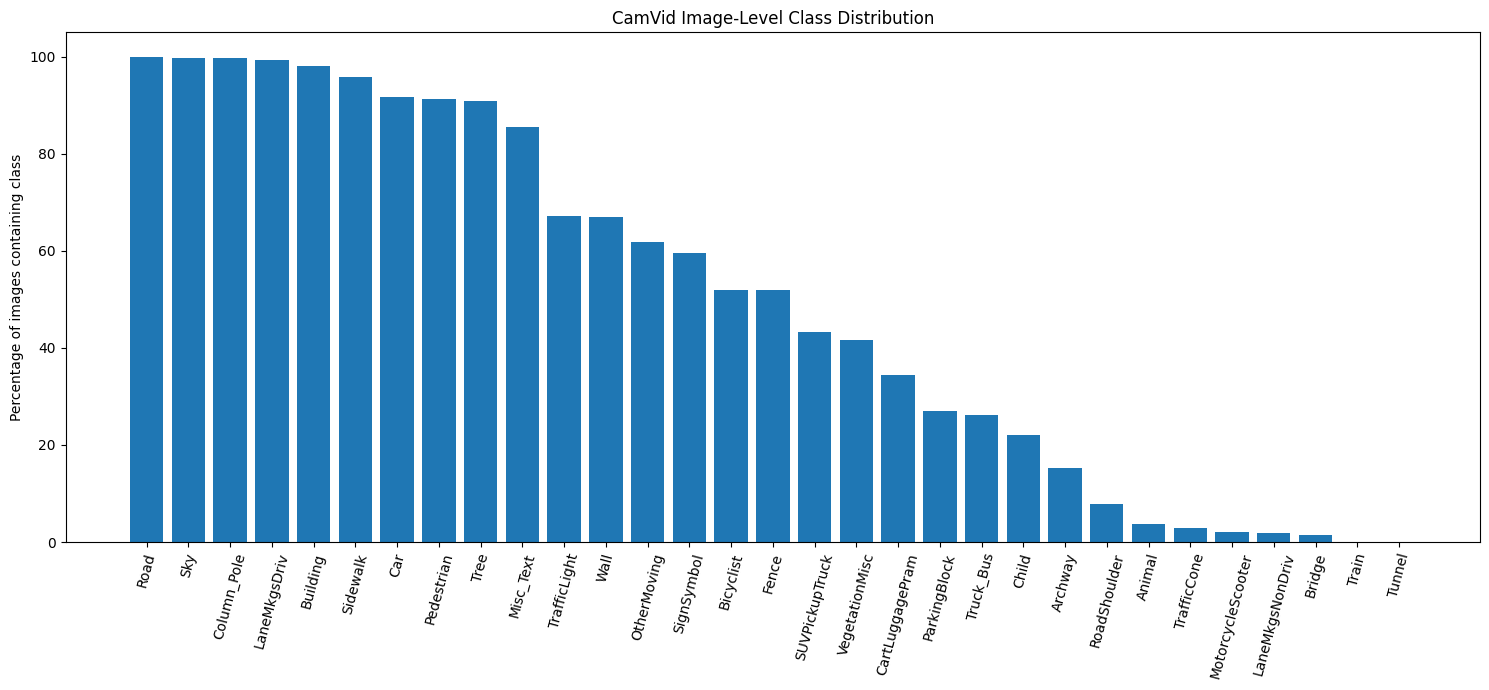

In [20]:
# Visualize
plt.figure(figsize=(15, 7))

plt.bar(
    class_distribution_df["Class"],
    class_distribution_df["Percentage"]
)

plt.xticks(rotation=75)
plt.ylabel("Percentage of images containing class")
plt.title("CamVid Image-Level Class Distribution")

plt.tight_layout()
plt.show()

## 14. Validate generated labels

In [21]:
# Every image must have at least one non-Void class.
positive_labels = image_labels_df[label_columns].sum(axis=1)

print("Images with no positive labels:",
      (positive_labels == 0).sum())

print("Images with at least one positive label:",
      (positive_labels > 0).sum())

# Check for classes that never appear.
zero_frequency_classes = [
    col
    for col in label_columns
    if image_labels_df[col].sum() == 0
]

print("Classes with zero image frequency:",
      zero_frequency_classes)

# Check target values.
assert set(
    image_labels_df[label_columns].values.flatten()
).issubset({0, 1})

print("Binary label validation passed.")

Images with no positive labels: 0
Images with at least one positive label: 701
Classes with zero image frequency: ['Train', 'Tunnel']
Binary label validation passed.


,number_of_classes
count,701.000000
mean,15.410842
std,2.544933
min,6.000000
25%,14.000000
50%,15.000000
75%,17.000000
max,21.000000


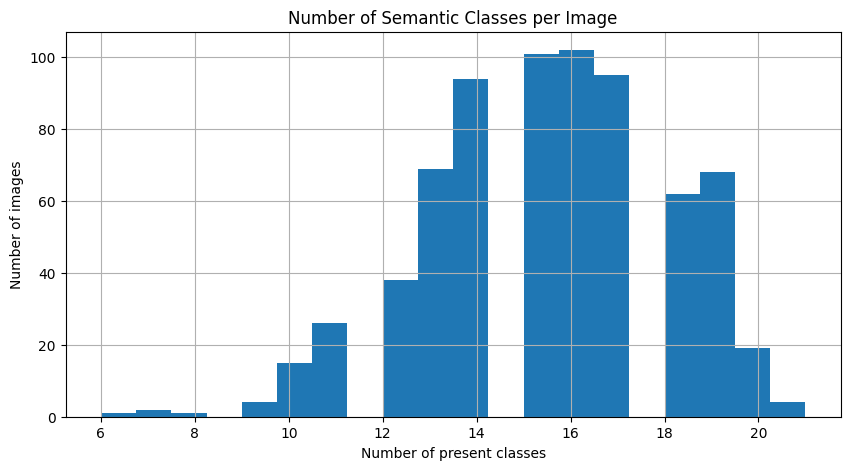

In [22]:
#Examine how many labels each image has:
image_labels_df["number_of_classes"] = (
    image_labels_df[label_columns].sum(axis=1)
)

display(
    image_labels_df["number_of_classes"].describe()
)

image_labels_df["number_of_classes"].hist(
    bins=20,
    figsize=(10, 5)
)

plt.title("Number of Semantic Classes per Image")
plt.xlabel("Number of present classes")
plt.ylabel("Number of images")
plt.show()

## 15. Save generated dataset artifacts

In [34]:
# Image-level multi-label targets
image_labels_df.to_csv(
    RESULTS_DIR / "image_labels.csv",
    index=False
)

# Class dictionary with generated IDs
class_mapping_df = class_df.copy()

class_mapping_df["class_id"] = (
    class_mapping_df["name"].map(CLASS_TO_ID)
)

class_mapping_df.loc[
    class_mapping_df["name"].str.lower() == "void",
    "class_id"
] = VOID_CLASS_ID

class_mapping_df.to_csv(
    RESULTS_DIR / "class_mapping.csv",
    index=False
)

# Class distribution
class_distribution_df.to_csv(
    RESULTS_DIR / "image_class_distribution.csv",
    index=False
)

# File pairing and inspection
inspection_df.to_csv(
    RESULTS_DIR / "image_mask_inspection.csv",
    index=False
)

# Missing file reports
pd.DataFrame({
    "missing_mask_for_image": missing_masks
}).to_csv(
    RESULTS_DIR / "missing_masks.csv",
    index=False
)

pd.DataFrame({
    "missing_image_for_mask": missing_images
}).to_csv(
    RESULTS_DIR / "missing_images.csv",
    index=False
)

detailed_labels_df.to_csv(
    RESULTS_DIR / "image_labels_detailed.csv",
    index=False
)

print("Artifacts saved under:", RESULTS_DIR)

Artifacts saved under: /content/drive/MyDrive/AAI-521/project/datasets/camvid/outputs
